Min Support: 0.001, Rules Generated: 29
Min Support: 0.002, Rules Generated: 14
Min Support: 0.002, Rules Generated: 14
Min Support: 0.003, Rules Generated: 9
Min Support: 0.003, Rules Generated: 9
Min Support: 0.004, Rules Generated: 7
Min Support: 0.004, Rules Generated: 7
Min Support: 0.005, Rules Generated: 6
Min Support: 0.005, Rules Generated: 6
Min Support: 0.006, Rules Generated: 2
Min Support: 0.006, Rules Generated: 2
Min Support: 0.007, Rules Generated: 2
Min Support: 0.007, Rules Generated: 2
Min Support: 0.008, Rules Generated: 2
Min Support: 0.008, Rules Generated: 2
Min Support: 0.009, Rules Generated: 1
Min Support: 0.009, Rules Generated: 1
Min Support: 0.010, Rules Generated: 1
Min Support: 0.010, Rules Generated: 1
Min Support: 0.011, Rules Generated: 1
Min Support: 0.011, Rules Generated: 1
Min Support: 0.012, Rules Generated: 1
Min Support: 0.012, Rules Generated: 1
Min Support: 0.013, Rules Generated: 1
Min Support: 0.013, Rules Generated: 1
Min Support: 0.014, Ru

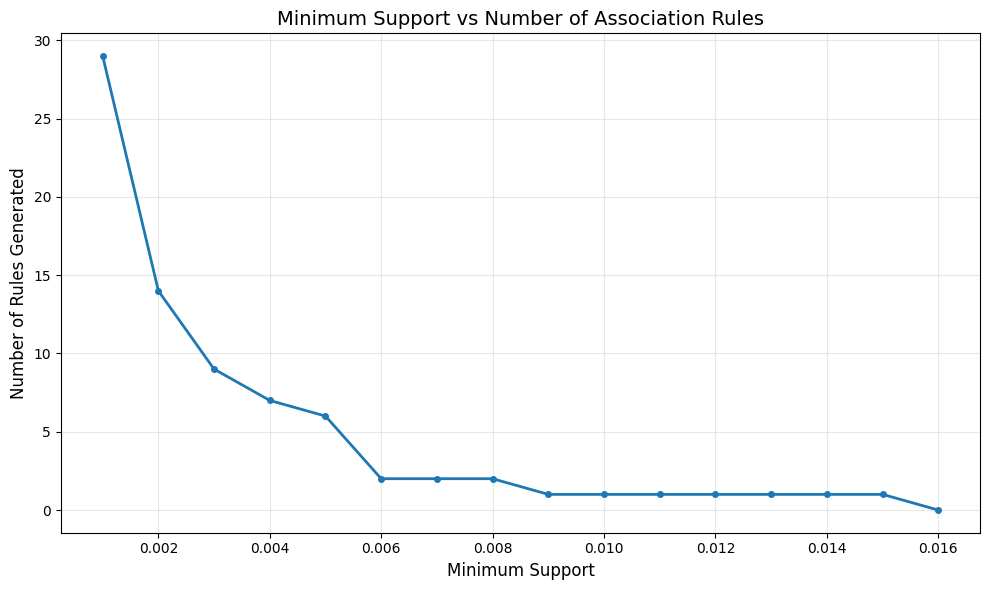


Total iterations: 16
Support range: 0.001 to 0.016


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# load data
store_data = pd.read_csv("store_data.csv")

# convert rows to list of items
transactions = []
for i in range(len(store_data)):
    row = []
    for j in range(len(store_data.columns)):
        item = store_data.iloc[i, j]
        if pd.notna(item):
            row.append(item)
    transactions.append(row)

total = len(transactions)
min_confidence = 0.2
min_lift = 3

def support_of(itemset, transactions, total):
    c = 0
    for t in transactions:
        ok = True
        for x in itemset:
            if x not in t:
                ok = False
                break
        if ok:
            c += 1
    return c / total

# Store results
support_values = []
rule_counts = []

min_support = 0.001
while True:
    # ----- FREQUENT 1-ITEMSETS -----
    item_counts = {}
    for t in transactions:
        for item in t:
            item_counts[item] = item_counts.get(item, 0) + 1
    
    L1 = []
    for item, count in item_counts.items():
        if count / total >= min_support:
            L1.append([item])
    
    # ----- FREQUENT 2-ITEMSETS (BRUTE FORCE) -----
    L2 = []
    for i in range(len(L1)):
        for j in range(i + 1, len(L1)):
            a = L1[i][0]
            b = L1[j][0]
            count = 0
            for t in transactions:
                if a in t and b in t:
                    count += 1
            support = count / total
            if support >= min_support:
                L2.append([a, b])
    
    # ----- ASSOCIATION RULES -----
    rule_count = 0
    for a, b in L2:
        sup_ab = support_of([a, b], transactions, total)
        sup_a = support_of([a], transactions, total)
        sup_b = support_of([b], transactions, total)
        
        conf = sup_ab / sup_a
        lift = conf / sup_b
    
        if conf >= min_confidence and lift >= min_lift:
            rule_count += 1
    
        conf = sup_ab / sup_b
        lift = conf / sup_a
    
        if conf >= min_confidence and lift >= min_lift:
            rule_count += 1
    
    support_values.append(min_support)
    rule_counts.append(rule_count)
    
    print(f"Min Support: {min_support:.3f}, Rules Generated: {rule_count}")
    
    if rule_count == 0:
        break
    
    min_support += 0.001

# Plot the curve
plt.figure(figsize=(10, 6))
plt.plot(support_values, rule_counts, marker='o', linestyle='-', linewidth=2, markersize=4)
plt.xlabel('Minimum Support', fontsize=12)
plt.ylabel('Number of Rules Generated', fontsize=12)
plt.title('Minimum Support vs Number of Association Rules', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nTotal iterations: {len(support_values)}")
print(f"Support range: {support_values[0]:.3f} to {support_values[-1]:.3f}")